pip install opencv-python numpy matplotlib plotly

# # Stereo Vision: disparity map -> point cloud
# Python port of slambook2 `ch5/stereoVision/stereoVision.cpp` (Listing 4.8, slambook-en p.92-93).
#
# Requirements: `pip install opencv-python numpy matplotlib plotly`
# Each `# %%` block is one notebook cell (works as-is in VS Code / Jupyter via jupytext,
# or just paste the cells into a notebook).

## camera calibration

  How Zhang's method works:
  1. Put a flat pattern with known geometry (the checkerboard) in front of the camera. Since the board is flat, you can set Z = 0 on it.
  2. Each view of the board gives a homography H between the board plane and the image.
  3. Each H gives two equations on the intrinsics K, so with 3 or more views you can solve for K in closed form.
  4. From there you get each view's pose (R, t), then refine everything with a nonlinear least-squares fit (Levenberg–Marquardt) that also estimates the distortion coefficients and minimizes reprojection
     error.

  It became the standard because it only needs a printed pattern, not a precise 3D calibration rig.

  For your setup:
  - Stereo: run Zhang's method on each lens, then cv2.stereoCalibrate to get R and T between the two lenses. That's still the same approach, done jointly.
  - Wide-angle lenses: the standard distortion model (k1, k2, p1, p2, k3) can struggle with your field of view. Try cv2.fisheye.calibrate / cv2.fisheye.stereoCalibrate, or the rational model
    (cv2.CALIB_RATIONAL_MODEL), and keep whichever gives the lower reprojection error.
  - Use a ChArUco board instead of a plain checkerboard. It's the same math, but every corner has an ID, so the board doesn't have to be fully visible in a frame. That makes it much easier to get corners
    into the distorted image edges, where fisheye calibration usually fails.
  - Kalibr (ETH) is the main alternative in robotics. It's more accurate for multi-camera or camera+IMU rigs, but heavier to set up. It's worth it if you later fuse an IMU on the XLeRobot.
  
  What decides the quality (more than which method you pick):
  - Use 20–40 views with the board tilted up to about 45° and covering the whole image, especially the corners.
  - Keep the board rigid and flat, and measure the square size accurately.
  - Avoid motion blur. Capture both lenses at the same moment, which a side-by-side stream already does.
  - Aim for an RMS reprojection error under about 0.5 px. If it's higher, drop the bad frames and run it again.

In [1]:
!pip install opencv-python numpy matplotlib plotly

In [2]:
import os
import urllib.request

import cv2
import numpy as np
import matplotlib.pyplot as plt

image size: (1080, 1920)


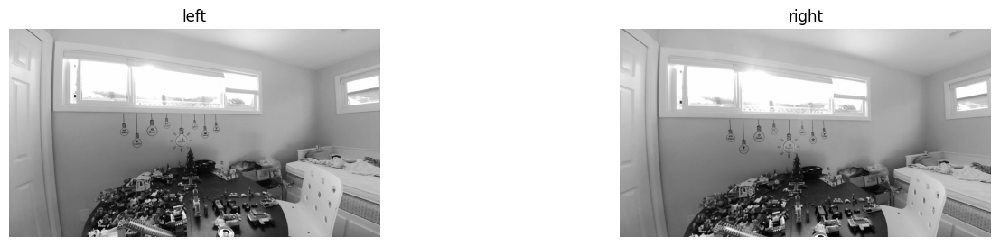

In [14]:
## 1. Get the left/right images (KITTI pair shipped with slambook2)
import json

DATA_DIR = "/content"

left = cv2.imread(os.path.join(DATA_DIR, "lens_image_left_half.png"), cv2.IMREAD_GRAYSCALE)
right = cv2.imread(os.path.join(DATA_DIR, "lens_image_right_half.png"), cv2.IMREAD_GRAYSCALE)

cal = json.load(open(os.path.join(DATA_DIR, "calibration_fisheye.json")))
K1 = np.array(cal["left"]["camera_matrix"]);  D1 = np.array(cal["left"]["distortion"]).reshape(4, 1)
K2 = np.array(cal["right"]["camera_matrix"]); D2 = np.array(cal["right"]["distortion"]).reshape(4, 1)
R = np.array(cal["stereo"]["R"]); T = np.array(cal["stereo"]["T_mm"]).reshape(3, 1) / 1000.0  # meters
size = (left.shape[1], left.shape[0])

# Rotate both views so matching points share a row, and remove fisheye distortion.
R1, R2, P1, P2, Q = cv2.fisheye.stereoRectify(K1, D1, K2, D2, size, R, T,
                                              flags=cv2.CALIB_ZERO_DISPARITY, balance=0.0)
map1 = cv2.fisheye.initUndistortRectifyMap(K1, D1, R1, P1, size, cv2.CV_16SC2)
map2 = cv2.fisheye.initUndistortRectifyMap(K2, D2, R2, P2, size, cv2.CV_16SC2)
left_r = cv2.remap(left, *map1, cv2.INTER_LINEAR)
right_r = cv2.remap(right, *map2, cv2.INTER_LINEAR)


print("image size:", left.shape)

fig, axes = plt.subplots(1, 2, figsize=(16, 3))
axes[0].imshow(left, cmap="gray"); axes[0].set_title("left")
axes[1].imshow(right, cmap="gray"); axes[1].set_title("right")
for ax in axes:
    ax.axis("off")
plt.show()

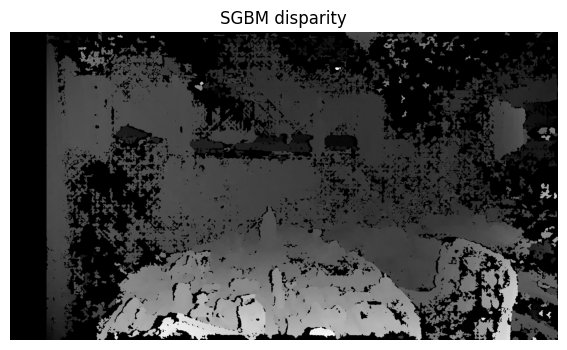

In [15]:
## 2. Intrinsics, baseline, and SGBM disparity

# %%
# intrinsics of left lens
fx, fy, cx, cy = 600.892, 604.389, 967.549, 522.636
# baseline (meters)
b = 0.06048

block_size, channels, num_disp = 7, 1, 128   # grayscale input: channels = 1
sgbm = cv2.StereoSGBM_create(minDisparity=0, numDisparities=num_disp, blockSize=block_size,
                             P1=8 * channels * block_size ** 2, P2=32 * channels * block_size ** 2,
                             disp12MaxDiff=1, preFilterCap=63, uniquenessRatio=10,
                             speckleWindowSize=100, speckleRange=2, mode=cv2.STEREO_SGBM_MODE_HH)
disparity = sgbm.compute(left_r, right_r).astype(np.float32) / 16.0

plt.figure(figsize=(16, 4))
plt.imshow(disparity / 96.0, cmap="gray", vmin=0, vmax=1)  # same as cv::imshow(disparity / 96.0)
plt.title("SGBM disparity")
plt.axis("off")
plt.show()

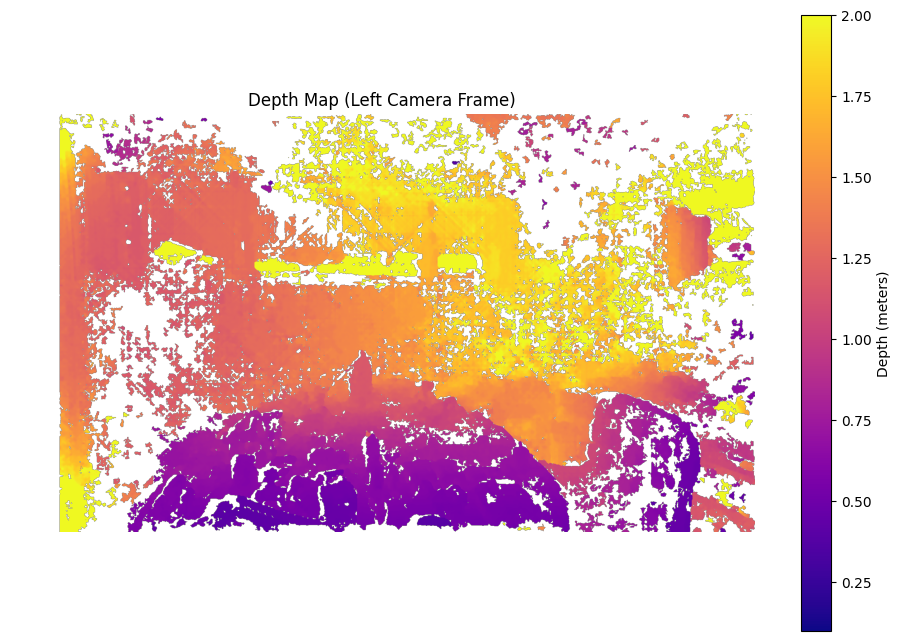

In [16]:
# Calculate the depth map using the formula: depth = (fx * b) / disparity
# We handle division by zero/negative disparity by masking invalid values.

# Depth from the rectified geometry: f and B come from P1/P2, not the raw fx and baseline.
f_rect = P1[0, 0]
b_rect = -P2[0, 3] / P2[0, 0]          # meters, about 0.0605
depth_map = np.full_like(disparity, np.nan)
valid = disparity > 0
depth_map[valid] = f_rect * b_rect / disparity[valid]


# Plot the depth map
plt.figure(figsize=(12, 8))
im = plt.imshow(depth_map, cmap="plasma", vmin=0.1, vmax=2.0)  # Adjust vmin/vmax to crop depth range for visualization
plt.colorbar(im, label="Depth (meters)")
plt.title("Depth Map (Left Camera Frame)")
plt.axis("off")
plt.show()

In [20]:
import plotly.graph_objects as go

# 3-D point for every pixel, in the rectified left camera frame (meters): x right, y down, z forward.
points = cv2.reprojectImageTo3D(disparity, Q)

# Colour each point from the rectified left image (load it in colour and rectify with the same map).
color = cv2.remap(cv2.imread(os.path.join(DATA_DIR, "lens_image_left_half.png")), *map1, cv2.INTER_LINEAR)
color = cv2.cvtColor(color, cv2.COLOR_BGR2RGB)

# Keep only valid, plausible points.
z = points[:, :, 2]
mask = (disparity > 0) & np.isfinite(z) & (z > 0.2) & (z < 3.0)

# A 1920x1080 image has ~2 million pixels; plot every 4th pixel in each direction so the browser stays responsive.
step = 4
sample = np.zeros_like(mask); sample[::step, ::step] = True
mask &= sample

xyz = points[mask]
rgb = color[mask]

fig = go.Figure(go.Scatter3d(
    # Show camera y (down) as -z (up), and camera z (forward) as depth into the scene.
    x=xyz[:, 0], y=xyz[:, 2], z=-xyz[:, 1],
    mode="markers",
    marker=dict(size=1.5, color=[f"rgb({r},{g},{b})" for r, g, b in rgb]),
))
fig.update_layout(scene=dict(xaxis_title="X right (m)", yaxis_title="Z forward (m)",
                             zaxis_title="up (m)", aspectmode="data"))
fig.show()          # or fig.write_html("point_cloud.html")

In [11]:
# ## 3. Disparity -> 3D points in the camera frame
# depth = fx * b / d,  X = (u - cx)/fx * depth,  Y = (v - cy)/fy * depth
#
# Vectorized with numpy instead of the double for-loop in the C++ code.

rows, cols = left.shape
v, u = np.mgrid[0:rows, 0:cols]

# keep only pixels with a sensible disparity (same thresholds as the book)
valid = (disparity > 5.0) & (disparity < 196.0)

d = disparity[valid]
depth = fx * b / d
x = (u[valid] - cx) / fx
y = (v[valid] - cy) / fy

# N x 4: [X, Y, Z, gray]  (the 4th dim is the color, like Vector4d in the C++ code)
pointcloud = np.column_stack([x * depth, y * depth, depth, left[valid] / 255.0])
print("point cloud size:", pointcloud.shape[0])

point cloud size: 578111


In [19]:
pointcloud.shape

(578111, 4)

In [12]:
# ## 4. Show the point cloud (replaces the Pangolin `showPointCloud`)
# Interactive plotly view; subsample so the browser stays responsive.

# %%
import plotly.graph_objects as go

STEP = 4  # increase if your notebook is slow
pc = pointcloud[::STEP]
gray = (pc[:, 3] * 255).astype(int)

fig = go.Figure(
    go.Scatter3d(
        # camera frame is x-right, y-down, z-forward; flip y so "up" looks up
        x=pc[:, 0], y=pc[:, 2], z=-pc[:, 1],
        mode="markers",
        marker=dict(size=1, color=[f"rgb({g},{g},{g})" for g in gray]),
    )
)
fig.update_layout(
    scene=dict(xaxis_title="X (right)", yaxis_title="Z (forward)", zaxis_title="-Y (up)",
               aspectmode="data", bgcolor="white"),
    height=700, margin=dict(l=0, r=0, t=0, b=0),
)
fig.show()
